# EXP-11 – Decision Tree: Classification Threshold (V1)

## 1. Mục tiêu thí nghiệm

Thí nghiệm EXP-11 khảo sát ảnh hưởng của việc điều chỉnh ngưỡng phân loại (Classification Threshold) đối với hiệu quả dự đoán của thuật toán Decision Tree trên bộ dữ liệu Bank Marketing. Thay vì sử dụng cố định ngưỡng mặc định 0,5, thí nghiệm lựa chọn ngưỡng dựa trên F1-score nhằm cải thiện sự cân bằng giữa Precision và Recall trong việc nhận diện khách hàng có đăng ký tiền gửi kỳ hạn.

Để đánh giá riêng tác động của ngưỡng phân loại, cấu hình Decision Tree được giữ nhất quán với EXP-03. Ngưỡng được lựa chọn từ xác suất dự đoán Out-of-Fold (OOF) trên tập huấn luyện thông qua Stratified 5-Fold Cross-validation, sau đó được áp dụng lên tập kiểm tra để đánh giá cuối cùng.

Các chỉ số đánh giá gồm Accuracy, Precision, Recall, F1-score và ROC-AUC.

## 2. Phương pháp thực hiện – Phiên bản V1

Phiên bản V1 triển khai theo cách tiếp cận cơ bản: dữ liệu được tiền xử lý trước bằng module dùng chung của nhóm; mô hình Decision Tree được đánh giá bằng Stratified 5-Fold Cross-validation trên tập huấn luyện; các ngưỡng từ 0,05 đến 0,60, với bước nhảy 0,05, được lần lượt kiểm tra bằng F1-score OOF. Ngưỡng có F1-score OOF cao nhất được chọn để phân loại xác suất trên tập kiểm tra.

Cách làm này kế thừa quy trình chọn ngưỡng trong notebook Random Forest của thành viên Huỳnh Quí Bảo và được điều chỉnh cho cấu hình Decision Tree của Phát. Vì bước tiền xử lý được fit trước khi chia các fold CV, V1 được xem là phiên bản triển khai ban đầu; hạn chế này sẽ được xem xét trong phiên bản V2.

## 3. Thư viện và cấu hình đường dẫn

Các thư viện được sử dụng để tiền xử lý dữ liệu, huấn luyện Decision Tree, thực hiện Cross-validation, đánh giá và lưu kết quả thí nghiệm. Thư mục gốc dự án được xác định tự động dựa trên sự hiện diện của `src/preprocessing.py` và dữ liệu đầu vào.

In [9]:
from pathlib import Path
from datetime import datetime
import sys
import json
import os

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)


def find_project_root():
    """Tìm thư mục dự án từ thư mục làm việc hiện tại hoặc các thư mục cha."""
    current = Path.cwd().resolve()
    candidates = [current, *current.parents]

    for candidate in candidates:
        preprocessing_file = candidate / "src" / "preprocessing.py"
        raw_data_file = candidate / "data" / "raw" / "bank-additional-full.csv"
        if preprocessing_file.is_file() and raw_data_file.is_file():
            return candidate

    raise FileNotFoundError(
        "Không tìm thấy thư mục gốc dự án. Hãy đặt notebook trong "
        "notebooks/Decision_Tree hoặc chạy Jupyter từ thư mục gốc dự án."
    )


ROOT_DIR = find_project_root()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.preprocessing import load_and_preprocess_data
from src.config import RESULTS_DIR, RANDOM_STATE

RAW_DATA_PATH = ROOT_DIR / "data" / "raw" / "bank-additional-full.csv"
RESULTS_DIR = Path(RESULTS_DIR)

print("Project root:", ROOT_DIR)
print("Raw data:", RAW_DATA_PATH)
print("Results root:", RESULTS_DIR)
print("Python:", sys.version.split()[0])

Project root: D:\#WS\Máy học\sgu2627k1_MayHoc\MayHoc_Nhom\Đồ án cuối kỳ
Raw data: D:\#WS\Máy học\sgu2627k1_MayHoc\MayHoc_Nhom\Đồ án cuối kỳ\data\raw\bank-additional-full.csv
Results root: D:\#WS\Máy học\sgu2627k1_MayHoc\MayHoc_Nhom\Đồ án cuối kỳ\notebooks\02_EDA\Experiments\Logs
Python: 3.15.0


## 4. Đọc và tiền xử lý dữ liệu

Dữ liệu được đọc từ `data/raw/bank-additional-full.csv` thông qua hàm `load_and_preprocess_data()` trong `src/preprocessing.py`. Hàm này thực hiện làm sạch cơ bản, loại bỏ biến `duration`, chia dữ liệu theo tỷ lệ 80:20 với `random_state=42` và áp dụng các bước mã hóa, chuẩn hóa.

Kết quả trả về gồm bảy thành phần: dữ liệu train/test đã tiền xử lý, nhãn train/test, dữ liệu train/test ở dạng thô và đối tượng preprocessor. Kết quả tiền xử lý của V1 được lưu trong thư mục chạy riêng để không ghi đè dữ liệu của các thí nghiệm khác.

In [10]:
# Tạo thư mục riêng cho mỗi lần chạy để không ghi đè kết quả cũ.
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
EXP11_ROOT = RESULTS_DIR / "Experiment_11_DecisionTree_threshold_V1"
RUN_DIR = EXP11_ROOT / f"run_{RUN_ID}"
RUN_DIR.mkdir(parents=True, exist_ok=False)

PROCESSED_DATA_DIR = RUN_DIR / "processed_data"

(
    X_train,
    X_test,
    y_train,
    y_test,
    X_train_raw,
    X_test_raw,
    preprocessor,
) = load_and_preprocess_data(
    filepath=str(RAW_DATA_PATH),
    save_dir=str(PROCESSED_DATA_DIR),
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("X_train_raw:", X_train_raw.shape)
print("X_test_raw:", X_test_raw.shape)
print("Train class distribution:", y_train.value_counts().to_dict())
print("Test class distribution:", y_test.value_counts().to_dict())
print("Run output directory:", RUN_DIR)

assert set(pd.Series(y_train).unique()) == {0, 1}, "Nhãn train phải được mã hóa thành 0/1."
assert set(pd.Series(y_test).unique()) == {0, 1}, "Nhãn test phải được mã hóa thành 0/1."

X_train: (32940, 62)
X_test: (8236, 62)
X_train_raw: (32940, 19)
X_test_raw: (8236, 19)
Train class distribution: {0: 29229, 1: 3711}
Test class distribution: {0: 7308, 1: 928}
Run output directory: D:\#WS\Máy học\sgu2627k1_MayHoc\MayHoc_Nhom\Đồ án cuối kỳ\notebooks\02_EDA\Experiments\Logs\Experiment_11_DecisionTree_threshold_V1\run_20261126_213505_321689


## 5. Khởi tạo Decision Tree và tạo xác suất OOF

Cấu hình mô hình được giữ giống EXP-03: `max_depth=8`, `min_samples_split=20`, `min_samples_leaf=10`, `class_weight="balanced"` và `random_state=42`. Stratified 5-Fold được sử dụng để giữ tỷ lệ hai lớp tương đối ổn định giữa các fold.

`cross_val_predict()` tạo xác suất dự đoán OOF cho từng quan sát trong tập huấn luyện. Các xác suất này được sử dụng để khảo sát ngưỡng; tập kiểm tra chưa được sử dụng trong quá trình lựa chọn ngưỡng.

In [11]:
# Giữ nguyên cấu hình Decision Tree của EXP-03.
model_dt_template = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Xác suất OOF của lớp 1 (khách hàng đăng ký: yes).
oof_probability_matrix = cross_val_predict(
    clone(model_dt_template),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1,
)

class_order = np.unique(np.asarray(y_train))
positive_class_index = int(np.where(class_order == 1)[0][0])
oof_probability = oof_probability_matrix[:, positive_class_index]

print("Số xác suất OOF:", len(oof_probability))
print("Số mẫu train:", len(y_train))
assert len(oof_probability) == len(y_train)

Số xác suất OOF: 32940
Số mẫu train: 32940


## 6. Khảo sát và lựa chọn ngưỡng phân loại

Các ngưỡng được khảo sát từ 0,05 đến 0,60 với bước nhảy 0,05. Tại mỗi ngưỡng, xác suất OOF được chuyển thành nhãn dự đoán và tính Precision, Recall, F1-score. Ngưỡng có F1-score cao nhất được lựa chọn cho bước đánh giá trên tập kiểm tra.

,Threshold,Precision,Recall,F1-score
0,0.05,0.1145,0.9811,0.2050
1,0.10,0.1157,0.9755,0.2069
2,0.15,0.1215,0.9598,0.2157
3,0.20,0.1268,0.9469,0.2237
4,0.25,0.1338,0.9151,0.2335
5,0.30,0.1457,0.8814,0.2501
6,0.35,0.2439,0.6933,0.3609
7,0.40,0.3261,0.6400,0.4321
8,0.45,0.3339,0.6365,0.4381
9,0.50,0.3430,0.6236,0.4425


Threshold được chọn: 0.60
F1-score OOF tại threshold được chọn: 0.4837
Threshold tốt nhất nằm ở cận trên của lưới khảo sát (0.60). Do đó, kết quả này có thể xem là tốt nhất trong phạm vi ngưỡng đã thử. 


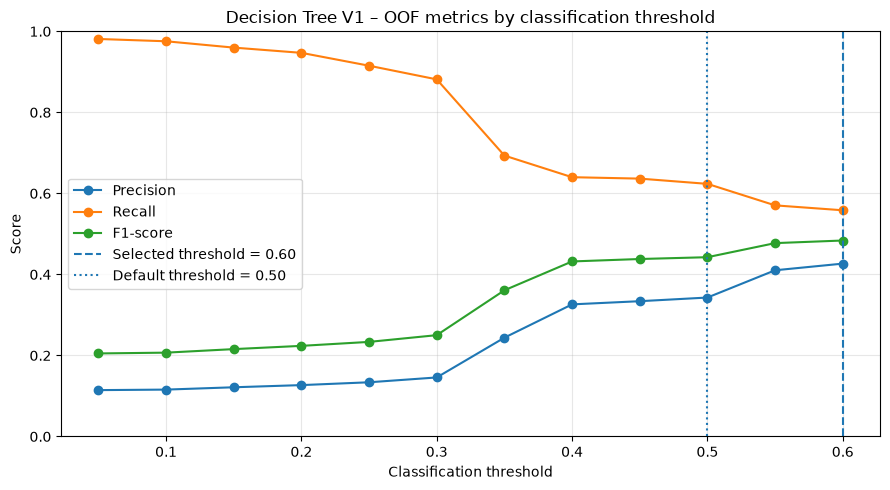

In [14]:
threshold_candidates = np.round(np.arange(0.05, 0.65, 0.05), 2)
threshold_rows = []

for threshold in threshold_candidates:
    oof_prediction = (oof_probability >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": float(threshold),
        "Precision": precision_score(y_train, oof_prediction, zero_division=0),
        "Recall": recall_score(y_train, oof_prediction, zero_division=0),
        "F1-score": f1_score(y_train, oof_prediction, zero_division=0),
    })

df_threshold = pd.DataFrame(threshold_rows)
display(df_threshold.round(4))

best_row_index = df_threshold["F1-score"].idxmax()
best_threshold = float(df_threshold.loc[best_row_index, "Threshold"])
best_oof_f1 = float(df_threshold.loc[best_row_index, "F1-score"])

print(f"Threshold được chọn: {best_threshold:.2f}")
print(f"F1-score OOF tại threshold được chọn: {best_oof_f1:.4f}")

if np.isclose(best_threshold, threshold_candidates[-1]):
    print(
        "Threshold tốt nhất nằm ở cận trên của lưới khảo sát (0.60). "
        "Do đó, kết quả này có thể xem là tốt nhất trong phạm vi ngưỡng đã thử. "
    )

plt.figure(figsize=(9, 5))
for metric_name in ["Precision", "Recall", "F1-score"]:
    plt.plot(
        df_threshold["Threshold"],
        df_threshold[metric_name],
        marker="o",
        label=metric_name,
    )
plt.axvline(best_threshold, linestyle="--", label=f"Selected threshold = {best_threshold:.2f}")
plt.axvline(0.50, linestyle=":", label="Default threshold = 0.50")
plt.title("Decision Tree V1 – OOF metrics by classification threshold")
plt.xlabel("Classification threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Nhận xét kết quả khảo sát ngưỡng

Kết quả khảo sát cho thấy Precision có xu hướng tăng khi threshold được nâng từ 0,05 lên 0,60, từ 0,1145 lên 0,4267. Ngược lại, Recall giảm từ 0,9811 xuống 0,5583. Điều này thể hiện sự đánh đổi giữa khả năng nhận diện được nhiều khách hàng đăng ký và mức độ chính xác của các dự đoán thuộc lớp đăng ký: ngưỡng càng cao thì mô hình càng thận trọng khi gán nhãn `Yes`.

F1-score tăng từ 0,2050 tại threshold 0,05 lên 0,4837 tại threshold 0,60. Trong phạm vi các ngưỡng đã khảo sát, 0,60 là giá trị cho F1-score cao nhất nên được chọn cho EXP-11 V1. Tuy nhiên, 0,60 cũng là cận trên của phạm vi thử nghiệm. Vì vậy, kết quả chỉ xác định đây là ngưỡng tốt nhất trong lưới khảo sát từ 0,05 đến 0,60, chưa đủ cơ sở kết luận đây là ngưỡng tối ưu trên toàn bộ khoảng [0, 1]. Đây là một hạn chế sẽ được xem xét ở phiên bản V2.

Các chỉ số trong bảng này được tính từ xác suất Out-of-Fold (OOF) trên tập huấn luyện để lựa chọn threshold. Chúng khác với các chỉ số ở phần đánh giá cuối cùng, vốn được tính trên tập kiểm tra độc lập. Do hai kết quả được tính trên các tập quan sát khác nhau, Precision, Recall và F1-score tại threshold 0,60 không nhất thiết trùng nhau.


## 7. Huấn luyện mô hình cuối cùng và đánh giá trên tập kiểm tra

Sau khi lựa chọn ngưỡng bằng dữ liệu OOF trên tập huấn luyện, Decision Tree được huấn luyện lại trên toàn bộ tập train. Xác suất dự đoán trên tập test được giữ nguyên; hai bộ nhãn được tạo ra để đối chiếu: nhãn mặc định do `predict()` trả về và nhãn sau khi áp dụng ngưỡng được lựa chọn.

ROC-AUC được tính từ xác suất dự đoán, do đó không thay đổi chỉ vì thay đổi ngưỡng phân loại.

In [15]:
def calculate_metrics(y_true, y_pred, y_probability):
    return {
        "Accuracy": float(accuracy_score(y_true, y_pred)),
        "Precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "Recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "F1-score": float(f1_score(y_true, y_pred, zero_division=0)),
        "ROC-AUC": float(roc_auc_score(y_true, y_probability)),
    }


model_dt_v1 = clone(model_dt_template)
model_dt_v1.fit(X_train, y_train)

class_index_test = int(np.where(model_dt_v1.classes_ == 1)[0][0])
y_probability_test = model_dt_v1.predict_proba(X_test)[:, class_index_test]

# Kết quả baseline dùng ngưỡng mặc định của DecisionTreeClassifier.predict().
y_prediction_default = model_dt_v1.predict(X_test)

# Kết quả EXP-11 V1 dùng threshold đã chọn từ OOF.
y_prediction_threshold = (y_probability_test >= best_threshold).astype(int)

y_test_array = np.asarray(y_test).ravel()

baseline_metrics = calculate_metrics(
    y_test_array,
    y_prediction_default,
    y_probability_test,
)

v1_metrics = calculate_metrics(
    y_test_array,
    y_prediction_threshold,
    y_probability_test,
)

print("EXP-03-style baseline metrics (threshold mặc định):")
display(pd.DataFrame([baseline_metrics], index=["Decision Tree – default threshold"]).round(4))

print(f"EXP-11 V1 metrics (threshold = {best_threshold:.2f}):")
display(pd.DataFrame([v1_metrics], index=["Decision Tree – EXP-11 V1"]).round(4))

EXP-03-style baseline metrics (threshold mặc định):


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Decision Tree – default threshold,0.8263,0.353,0.6509,0.4577,0.7932


EXP-11 V1 metrics (threshold = 0.60):


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Decision Tree – EXP-11 V1,0.8757,0.4591,0.5808,0.5128,0.7932


## 8. Biểu đồ đánh giá và nhận xét

Confusion Matrix thể hiện số lượng dự đoán đúng và sai của từng lớp sau khi áp dụng threshold 0,60. ROC Curve được xây dựng từ xác suất dự đoán trên tập kiểm tra, qua đó phản ánh khả năng phân biệt hai lớp của mô hình ở nhiều ngưỡng phân loại khác nhau.


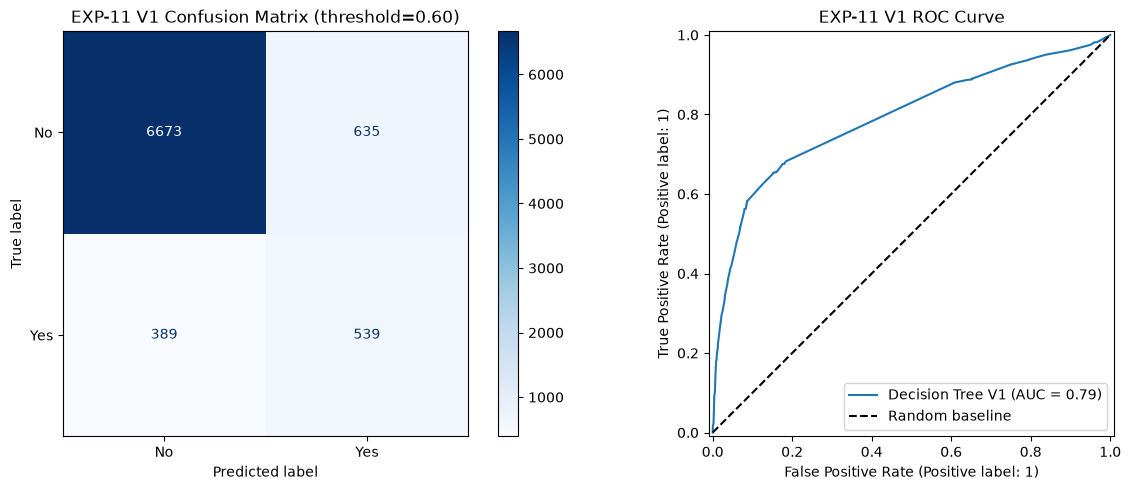

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test_array,
    y_prediction_threshold,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0],
    values_format="d",
)
axes[0].set_title(f"EXP-11 V1 Confusion Matrix (threshold={best_threshold:.2f})")

RocCurveDisplay.from_predictions(
    y_test_array,
    y_probability_test,
    name="Decision Tree V1",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("EXP-11 V1 ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### Nhận xét biểu đồ

**Confusion Matrix:** Khi sử dụng threshold 0,60 thay cho quy tắc phân loại mặc định, mô hình trở nên thận trọng hơn khi dự đoán khách hàng thuộc lớp `Yes`. Kết quả trên tập kiểm tra thể hiện qua Precision tăng từ 0,3530 lên 0,4591, trong khi Recall giảm từ 0,6509 xuống 0,5808. Điều này cho thấy tỷ lệ dự đoán `Yes` chính xác hơn, nhưng mô hình đồng thời bỏ sót một phần khách hàng thực sự đăng ký nhiều hơn so với baseline. Trên ma trận nhầm lẫn, xu hướng tương ứng là số dự đoán dương tính giả giảm hoặc không tăng, trong khi số âm tính giả tăng hoặc không giảm. Việc lựa chọn ngưỡng vì vậy phụ thuộc vào mức độ ưu tiên giữa hạn chế dự đoán nhầm và phát hiện được nhiều khách hàng tiềm năng.

**ROC Curve:** ROC-AUC của EXP-11 V1 là 0,7932, bằng với EXP-03 Baseline. Điều này phù hợp với cách triển khai của thí nghiệm: mô hình và xác suất dự đoán trên tập kiểm tra được giữ nguyên, chỉ thay đổi threshold dùng để chuyển xác suất thành nhãn. ROC Curve được xây dựng từ xác suất, không phải từ nhãn sau khi áp dụng một threshold cố định, nên việc thay đổi threshold không làm thay đổi đường ROC hoặc ROC-AUC.


## 9. Lưu kết quả thí nghiệm tự động

Mỗi lần chạy notebook tạo một thư mục kết quả riêng theo thời gian thực hiện. Các tệp cấu hình, chỉ số đánh giá, xác suất và nhãn dự đoán, bảng khảo sát ngưỡng, mô hình và preprocessor được lưu để phục vụ đối chiếu và tái sử dụng.

In [ ]:
experiment_params = {
    **model_dt_v1.get_params(),
    "experiment": "EXP-11 Decision Tree Threshold V1",
    "selected_threshold": best_threshold,
    "threshold_selection_metric": "F1-score",
    "threshold_candidates": threshold_candidates.tolist(),
    "oof_f1_at_selected_threshold": best_oof_f1,
    "cross_validation": {
        "method": "StratifiedKFold",
        "n_splits": 5,
        "shuffle": True,
        "random_state": RANDOM_STATE,
    },
    "preprocessing_note": (
        "V1 sử dụng preprocessor đã fit trên toàn bộ tập train trước khi chạy CV; "
        "đây là phiên bản cơ bản, sẽ được cải thiện trong V2."
    ),
}

# metrics.json và metrics.csv: kết quả cuối cùng trên tập test.
with open(RUN_DIR / "params_cfg.json", "w", encoding="utf-8") as file:
    json.dump(experiment_params, file, ensure_ascii=False, indent=2, default=str)

with open(RUN_DIR / "metrics.json", "w", encoding="utf-8") as file:
    json.dump(v1_metrics, file, ensure_ascii=False, indent=2)

pd.DataFrame([v1_metrics]).round(4).to_csv(
    RUN_DIR / "metrics.csv",
    index=False,
)

# Bảng khảo sát ngưỡng từ xác suất OOF.
df_threshold.to_csv(RUN_DIR / "threshold_scan_oof.csv", index=False)

# Kết quả dự đoán trên tập test.
pd.DataFrame({
    "y_true": y_test_array,
    "y_pred_default": np.asarray(y_prediction_default).ravel(),
    "y_pred_threshold": np.asarray(y_prediction_threshold).ravel(),
    "y_probability_yes": np.asarray(y_probability_test).ravel(),
}).to_csv(RUN_DIR / "predictions.csv", index=False)

# Lưu model và preprocessor riêng; threshold được lưu trong params_cfg.json.
joblib.dump(model_dt_v1, RUN_DIR / "best_model.pkl")
joblib.dump(preprocessor, RUN_DIR / "preprocessor.pkl")

# Lưu gói đầy đủ để thuận tiện khi tái sử dụng.
joblib.dump({
    "preprocessor": preprocessor,
    "model": model_dt_v1,
    "threshold": best_threshold,
}, RUN_DIR / "model_bundle.pkl")

# Lưu biểu đồ tổng hợp.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_array,
    y_prediction_threshold,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0],
    values_format="d",
)
axes[0].set_title(f"Confusion Matrix (threshold={best_threshold:.2f})")
RocCurveDisplay.from_predictions(
    y_test_array,
    y_probability_test,
    name="Decision Tree V1",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("ROC Curve")
plt.tight_layout()
fig.savefig(RUN_DIR / "confusion_roc.png", dpi=150, bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
for metric_name in ["Precision", "Recall", "F1-score"]:
    ax.plot(df_threshold["Threshold"], df_threshold[metric_name], marker="o", label=metric_name)
ax.axvline(best_threshold, linestyle="--", label=f"Selected = {best_threshold:.2f}")
ax.axvline(0.5, linestyle=":", label="Default = 0.50")
ax.set_title("OOF metrics by threshold")
ax.set_xlabel("Threshold")
ax.set_ylabel("Score")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / "threshold_metrics.png", dpi=150, bbox_inches="tight")
plt.close(fig)

print("Đã lưu kết quả EXP-11 V1 tại:", RUN_DIR)
print("Các tệp đã tạo:")
for path in sorted(RUN_DIR.iterdir()):
    if path.is_file():
        print("-", path.name)

Đã lưu kết quả EXP-11 V1 tại: D:\#WS\Máy học\sgu2627k1_MayHoc\MayHoc_Nhom\Đồ án cuối kỳ\notebooks\02_EDA\Experiments\Logs\Experiment_11_DecisionTree_threshold_V1\run_20261126_213505_321689
Các tệp đã tạo:
- best_model.pkl
- confusion_roc.png
- metrics.csv
- metrics.json
- model_bundle.pkl
- params_cfg.json
- predictions.csv
- preprocessor.pkl
- threshold_metrics.png
- threshold_scan_oof.csv


## 10. So sánh với Decision Tree Baseline (EXP-03)

Kết quả của EXP-11 V1 được so sánh với mô hình Decision Tree Baseline sử dụng ngưỡng mặc định. Hai kết quả được tính trên cùng tập kiểm tra và cùng cấu hình mô hình; khác biệt chính là cách chuyển xác suất dự đoán thành nhãn phân loại.

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,EXP-03 – Decision Tree Baseline,0.8263,0.3530,0.6509,0.4577,0.7932
1,EXP-11 V1 – Threshold 0.60,0.8757,0.4591,0.5808,0.5128,0.7932


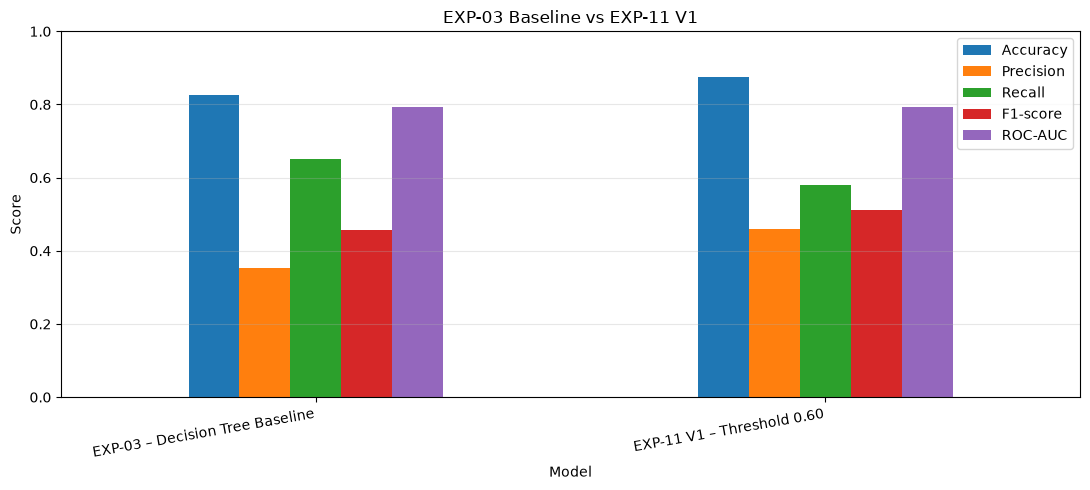

In [18]:
comparison_df = pd.DataFrame([
    {"Model": "EXP-03 – Decision Tree Baseline", **baseline_metrics},
    {"Model": f"EXP-11 V1 – Threshold {best_threshold:.2f}", **v1_metrics},
])
display(comparison_df.round(4))
comparison_df.to_csv(RUN_DIR / "comparison_exp03_vs_exp11_v1.csv", index=False)

metric_columns = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
ax = comparison_df.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(11, 5),
)
ax.set_title("EXP-03 Baseline vs EXP-11 V1")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()

## 11. Nhận xét và so sánh kết quả EXP-11 V1

Kết quả trên cùng tập kiểm tra cho thấy việc điều chỉnh threshold từ quy tắc mặc định của EXP-03 sang 0,60 ở EXP-11 V1 tạo ra sự thay đổi rõ rệt trong hiệu quả phân loại. Accuracy tăng từ 0,8263 lên 0,8757, tương ứng tăng 0,0494 (4,94 điểm phần trăm). Precision tăng từ 0,3530 lên 0,4591, tức tăng 0,1061 (10,61 điểm phần trăm). F1-score cũng tăng từ 0,4577 lên 0,5128, tương ứng tăng 0,0551 (5,51 điểm phần trăm).

Ở chiều ngược lại, Recall giảm từ 0,6509 xuống 0,5808, tương ứng giảm 0,0701 (7,01 điểm phần trăm). Điều này cho thấy threshold 0,60 giúp mô hình thận trọng hơn khi dự đoán khách hàng đăng ký: các dự đoán thuộc lớp `Yes` có độ chính xác cao hơn, nhưng khả năng phát hiện toàn bộ khách hàng thực sự đăng ký giảm so với baseline. Vì mục tiêu của thí nghiệm là tối ưu F1-score, mức tăng F1-score cho thấy sự cân bằng giữa Precision và Recall trên tập kiểm tra được cải thiện, dù Recall phải đánh đổi.

ROC-AUC giữ nguyên ở mức 0,7932. Nguyên nhân là EXP-03 và EXP-11 V1 sử dụng cùng mô hình đã huấn luyện và cùng xác suất dự đoán; thí nghiệm chỉ thay đổi threshold để tạo nhãn phân loại. Do đó, khả năng xếp hạng/phân biệt hai lớp được phản ánh bởi ROC-AUC không thay đổi.

Nhìn chung, với các chỉ số trên tập kiểm tra, EXP-11 V1 cải thiện Accuracy, Precision và F1-score so với EXP-03, nhưng không cải thiện Recall. Vì vậy, không thể kết luận threshold 0,60 tốt hơn trên mọi khía cạnh; mức threshold phù hợp cần được xem xét theo mục tiêu ưu tiên của bài toán. Các số liệu này cũng cần được đọc cùng kết quả khảo sát OOF ở phần 6: bảng OOF phục vụ lựa chọn threshold trên tập huấn luyện, còn bảng so sánh tại phần này phản ánh đánh giá cuối cùng trên tập kiểm tra.


## 12. Kết luận và hướng cải tiến

EXP-11 V1 đã khảo sát ảnh hưởng của threshold đến kết quả phân loại của Decision Tree bằng cách sử dụng xác suất OOF trên tập huấn luyện. Trong phạm vi ngưỡng từ 0,05 đến 0,60 với bước nhảy 0,05, threshold 0,60 đạt F1-score OOF cao nhất là 0,4837 và được lựa chọn để đánh giá trên tập kiểm tra. Do giá trị được chọn nằm ở cận trên của phạm vi khảo sát, kết quả V1 chưa khẳng định được ngưỡng tối ưu trên toàn bộ khoảng có thể có.

Trên tập kiểm tra, EXP-11 V1 đạt Accuracy 0,8757, Precision 0,4591, Recall 0,5808, F1-score 0,5128 và ROC-AUC 0,7932. So với EXP-03, Accuracy, Precision và F1-score tăng; Recall giảm; ROC-AUC không thay đổi. Kết quả cho thấy việc điều chỉnh threshold đã thay đổi sự cân bằng giữa Precision và Recall mà không làm thay đổi mô hình Decision Tree hoặc thứ tự xác suất dự đoán.

V1 là phiên bản triển khai ban đầu và còn hai hạn chế chính. Thứ nhất, threshold chỉ được khảo sát trong phạm vi 0,05–0,60 với bước nhảy 0,05 nên độ chi tiết và phạm vi tìm kiếm còn giới hạn. Thứ hai, dữ liệu đã được tiền xử lý trước khi thực hiện Cross-validation; vì vậy, preprocessor đã được fit trên toàn bộ tập train trước khi chia fold. Ở V2, quy trình sẽ được cải thiện bằng cách đặt bước tiền xử lý và Decision Tree trong cùng Pipeline để mỗi fold chỉ fit preprocessor trên phần dữ liệu huấn luyện của fold đó. Phạm vi và độ chi tiết khảo sát threshold cũng sẽ được xem xét mở rộng. V2 được thực hiện trong notebook độc lập để có thể đối chiếu hai cách triển khai mà không làm thay đổi kết quả V1.
